# Base 3: exploração, ACF, STL e tratamento

Este notebook transforma apenas a entrada estrutural da Base 3 em um CSV `cleaned`, sem alterar os arquivos congelados. A ACF e a STL usam o maior segmento regular e completo do alvo, sem preencher ausências somente para gerar gráfico.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "configs").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from discovery_series_temporais.cleaning import build_cleaned_dataset, plot_cleaned_diagnostics

BASE_ID = 3
cleaned, summary = build_cleaned_dataset(BASE_ID, ROOT / "data" / "processed")
display(pd.DataFrame([{
    "base": summary.base_id,
    "target_original": summary.target_name,
    "rows": summary.rows,
    "columns": summary.columns,
    "missing_target": summary.missing_target,
    "cleaned_output": str(summary.output_path),
    "actions": "; ".join(summary.actions),
}]))
display(cleaned.head())
display(cleaned.isna().sum().rename("missing_values").to_frame())


,base,target_original,rows,columns,missing_target,cleaned_output,actions
0,3,PM2.5,35064,13,925,C:\Users\mayumishimizu-ieg\.codex\.chatgpt-pro...,retained the hourly target and observed extern...


,timestamp,target,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM
0,2013-03-01 00:00:00,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4
1,2013-03-01 01:00:00,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7
2,2013-03-01 02:00:00,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6
3,2013-03-01 03:00:00,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1
4,2013-03-01 04:00:00,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0


,missing_values
timestamp,0
target,925
PM10,718
SO2,935
NO2,1023
CO,1776
O3,1719
TEMP,20
PRES,20
DEWP,20


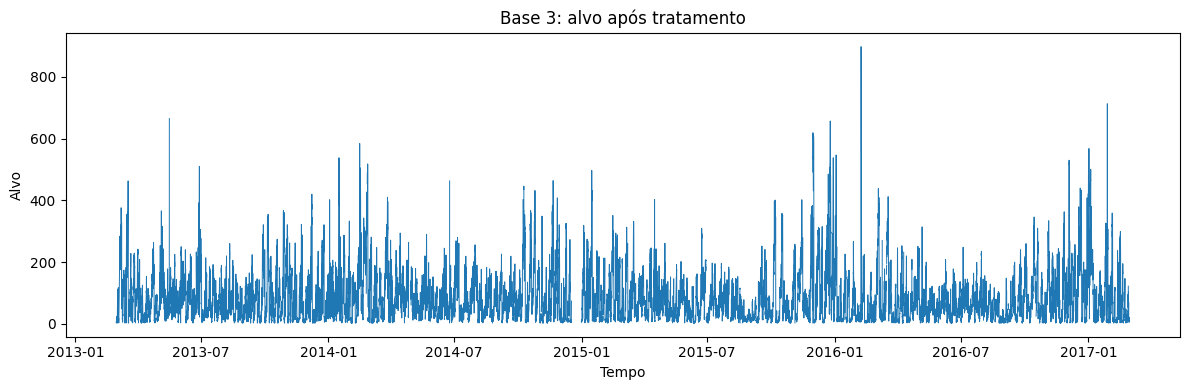

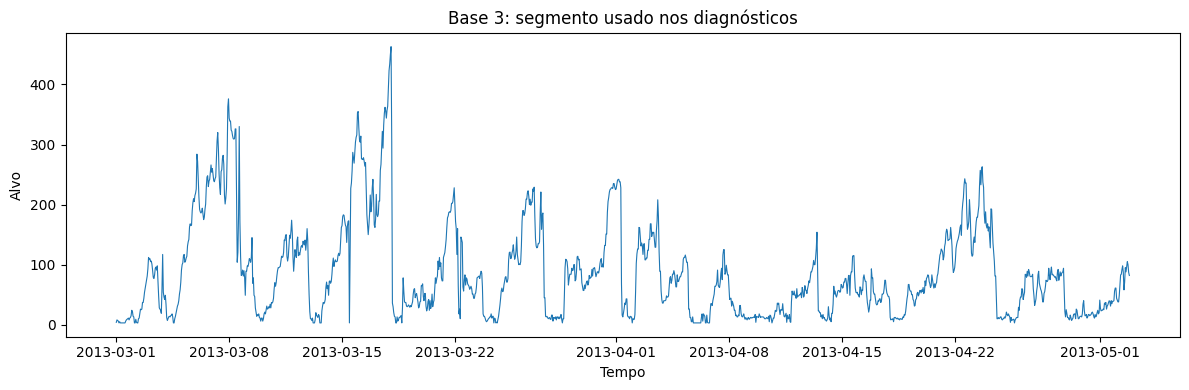

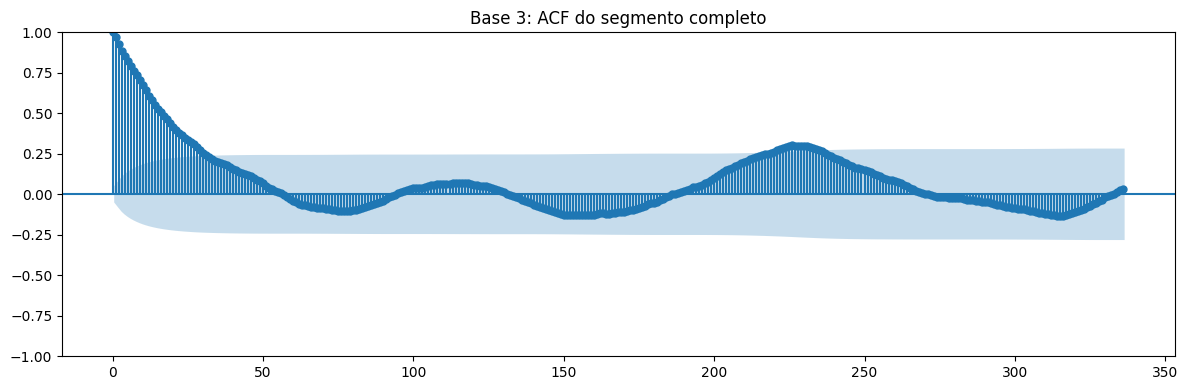

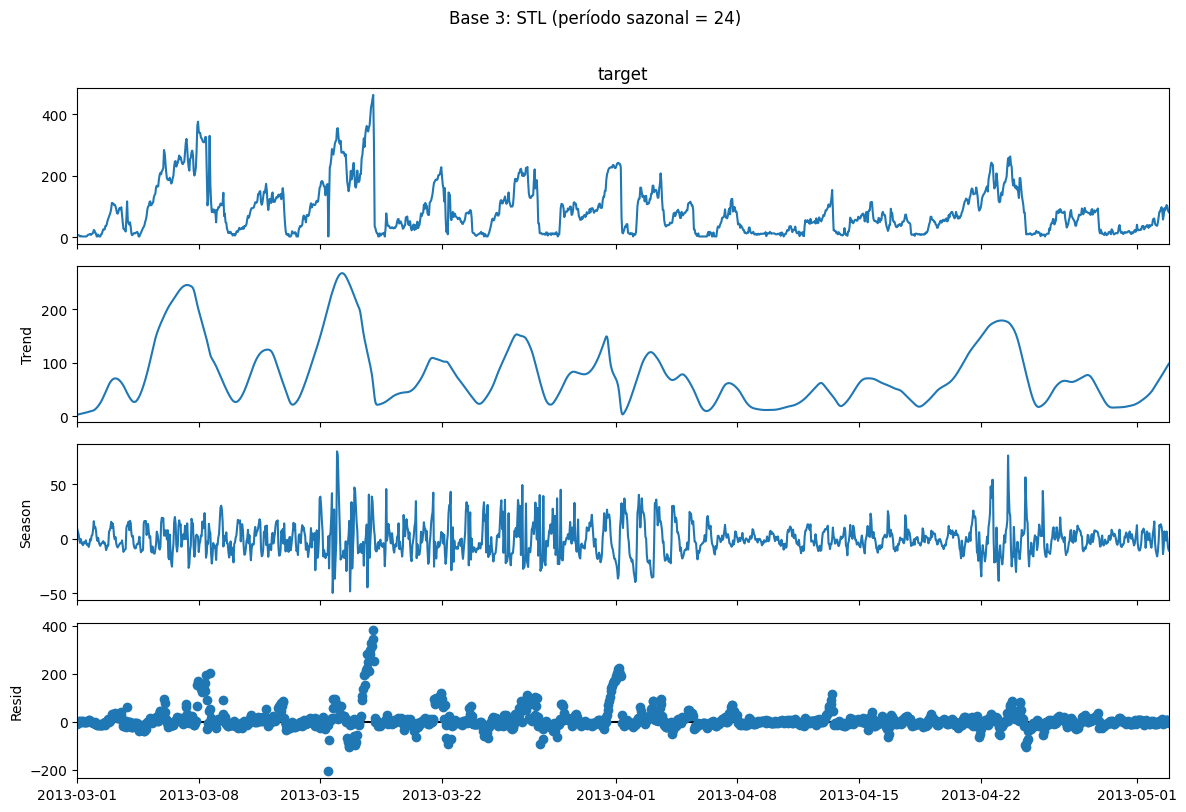

,segment_start,segment_end,segment_points,stl_seasonal_period,acf_lags
0,2013-03-01,2013-05-02 20:00:00,1509,24,336


In [2]:
figure, axis = plt.subplots(figsize=(12, 4))
axis.plot(cleaned["timestamp"], cleaned["target"], linewidth=0.7)
axis.set(title=f"Base {BASE_ID}: alvo após tratamento", xlabel="Tempo", ylabel="Alvo")
figure.tight_layout()
plt.show()

diagnostic = plot_cleaned_diagnostics(
    cleaned,
    BASE_ID,
    ROOT / "reports" / "generated" / "exploration" / f"base{BASE_ID}",
)
display(pd.DataFrame([{
    "segment_start": diagnostic.data["timestamp"].min(),
    "segment_end": diagnostic.data["timestamp"].max(),
    "segment_points": len(diagnostic.data),
    "stl_seasonal_period": diagnostic.seasonal_period,
    "acf_lags": diagnostic.acf_lags,
}]))
